# 01. Exploratory Data Analysis & Order Book Audit (Rounds 0–5)

Before proposing any pricing model or parameter grid, we audit all 34 raw CSV files under `data/raw/prosperity4/` for schema integrity, SHA-256 provenance, missing-side order-book regimes, quoted spread distributions, and cross-round structural transitions from Round 0 through Round 5.

### Research Questions
1. Are all timestamps uniformly spaced (`step = 100`) and free of crossed L1 books ($P_{\text{bid}, 1} \ge P_{\text{ask}, 1}$)?
2. How do missing-side regimes (`one_sided` and empty `mid_price == 0.0` ticks) evolve across Rounds 0–5, and why do naive CSV `mid_price` returns corrupt volatility estimates?
3. How does liquidity scale across market regimes: from `2` instruments (`R0–R2`) to `12` spot/options (`R3–R4`) and `50` category-grouped instruments (`R5`)?

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.analysis import summarize_order_book
from prosperity_toolkit.data.loader import DataLoader

loader = DataLoader(data_root=root / "data")
manifest = json.loads((root / "data" / "manifests" / "prosperity4_manifest.json").read_text())
m_df = pd.DataFrame(manifest["files"])
print(f"Manifest verified: {manifest['total_files']} files, all_valid={manifest['all_valid']}")

round_summary = (
    m_df.groupby(["round_num", "dataset_type"], as_index=False)
    .agg(
        files=("filepath", "count"),
        total_rows=("row_count", "sum"),
        duplicates=("duplicate_count", "sum"),
        one_sided=("one_sided_ticks", "sum"),
        empty_books=("empty_book_ticks", "sum"),
        zero_px_trades=("zero_price_trades", "sum"),
        buyer_ids=("unique_buyer_ids", "max"),
    )
)
display(round_summary)

Manifest verified: 34 files, all_valid=True


,round_num,dataset_type,files,total_rows,duplicates,one_sided,empty_books,zero_px_trades,buyer_ids
0,0,prices,2,40000,0,0,0,0,0
1,0,trades,2,1219,0,0,0,0,0
2,1,prices,3,60000,0,4565,103,0,0
3,1,trades,3,2276,2,0,0,0,0
4,2,prices,3,60000,0,4468,100,0,0
5,2,trades,3,2391,0,0,0,0,0
6,3,prices,3,360000,0,0,0,0,0
7,3,trades,3,4048,0,0,0,568,0
8,4,prices,3,360000,0,0,0,0,0
9,4,trades,3,4281,0,0,0,639,7


## 1. Round 0–1 Micro-Audit & L1–L2 Ladder Structure (In-Sample)

Round 0 (`EMERALDS`, `TOMATOES`) exhibits `100%` two-sided books, whereas Round 1 (`ASH_COATED_OSMIUM`, `INTARIAN_PEPPER_ROOT`) drops into `726–795` one-sided ticks and `14–21` completely empty ticks per 10,000-step day. Moreover, Round 1 median quoted spreads sit at `16` ticks (`ASH_COATED_OSMIUM`) and `12–13` ticks (`INTARIAN_PEPPER_ROOT`), with frequent thin inside-spread quotes sitting `2–3` ticks ahead of heavy market-maker walls. Below we inspect the Round 0–1 per-day summary alongside the strictly in-sample (`Day -2` & `Day -1`) spread and L1–L2 gap histograms.

,round,day,product,two_sided,one_sided,empty,mid_mean,mid_std,spread_mean,spread_med,l1_bid_vol,l1_ask_vol,valid
0,0,-2,EMERALDS,10000,0,0,10000.00,0.73,15.73,16.0,12.46,12.46,True
1,0,-2,TOMATOES,10000,0,0,5007.95,10.29,13.07,13.0,7.43,7.43,True
2,0,-1,EMERALDS,10000,0,0,10000.00,0.72,15.74,16.0,12.46,12.46,True
3,0,-1,TOMATOES,10000,0,0,4977.57,14.58,12.98,13.0,7.45,7.46,True
4,1,-2,ASH_COATED_OSMIUM,9187,795,18,9998.16,4.73,16.15,16.0,14.04,14.18,True
5,1,-2,INTARIAN_PEPPER_ROOT,9216,768,16,10500.57,287.93,11.99,12.0,11.53,11.52,True
6,1,-1,ASH_COATED_OSMIUM,9225,758,17,10000.83,3.83,16.19,16.0,14.17,14.17,True
7,1,-1,INTARIAN_PEPPER_ROOT,9219,764,17,11501.41,287.64,13.01,13.0,11.53,11.51,True
8,1,0,ASH_COATED_OSMIUM,9232,754,14,10001.62,5.22,16.18,16.0,14.16,14.14,True
9,1,0,INTARIAN_PEPPER_ROOT,9253,726,21,12500.96,288.19,14.13,14.0,11.57,11.53,True


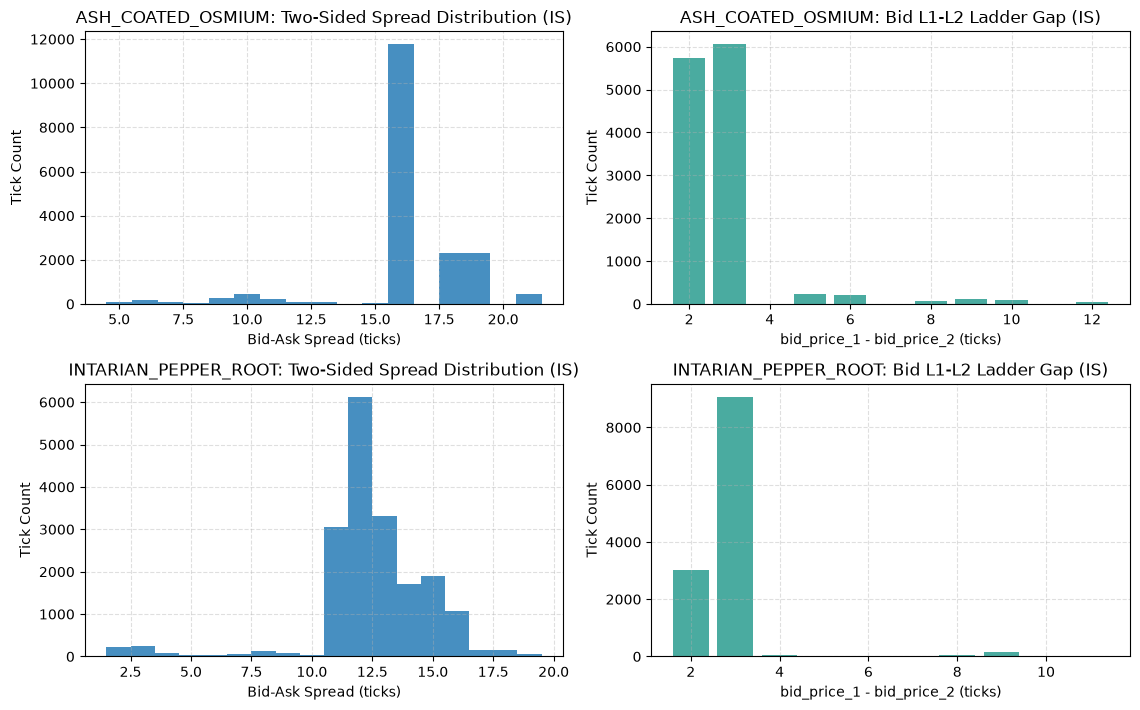

In [2]:
rows = []
for rnd, days in [(0, [-2, -1]), (1, [-2, -1, 0])]:
    for day in days:
        p_path = root / "data" / "raw" / "prosperity4" / f"round{rnd}" / f"prices_round_{rnd}_day_{day}.csv"
        df, rep = DataLoader.ingest_csv(p_path)
        for prod in sorted(df["product"].unique()):
            b = summarize_order_book(df, prod)
            rows.append({
                "round": rnd,
                "day": day,
                "product": prod,
                "two_sided": b.two_sided_ticks,
                "one_sided": b.one_sided_ticks,
                "empty": b.empty_ticks,
                "mid_mean": round(b.mid_mean, 2),
                "mid_std": round(b.mid_std, 2),
                "spread_mean": round(b.spread_mean, 2),
                "spread_med": b.spread_median,
                "l1_bid_vol": round(b.avg_bid_depth_l1, 2),
                "l1_ask_vol": round(b.avg_ask_depth_l1, 2),
                "valid": rep.is_valid,
            })

display(pd.DataFrame(rows))

is_r1 = pd.concat([loader.load_day_prices(1, -2), loader.load_day_prices(1, -1)], ignore_index=True)
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.2))
for row_idx, sym in enumerate(["ASH_COATED_OSMIUM", "INTARIAN_PEPPER_ROOT"]):
    sub = is_r1[is_r1["product"] == sym]
    valid = sub.loc[sub["bid_price_1"].notna() & sub["ask_price_1"].notna()]
    spread = valid["ask_price_1"] - valid["bid_price_1"]
    gap12 = (valid["bid_price_1"] - valid["bid_price_2"]).dropna()

    axes[row_idx, 0].hist(spread, bins=range(int(spread.min()), int(spread.max()) + 2), align="left", alpha=0.82)
    axes[row_idx, 0].set_title(f"{sym}: Two-Sided Spread Distribution (IS)")
    axes[row_idx, 0].set_xlabel("Bid-Ask Spread (ticks)")
    axes[row_idx, 0].set_ylabel("Tick Count")
    axes[row_idx, 0].grid(True, linestyle="--", alpha=0.4)

    vc = gap12.value_counts().sort_index().head(10)
    axes[row_idx, 1].bar(vc.index.astype(int), vc.values, color="#2a9d8f", alpha=0.85)
    axes[row_idx, 1].set_title(f"{sym}: Bid L1-L2 Ladder Gap (IS)")
    axes[row_idx, 1].set_xlabel("bid_price_1 - bid_price_2 (ticks)")
    axes[row_idx, 1].set_ylabel("Tick Count")
    axes[row_idx, 1].grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()

## 2. Cross-Round Liquidity Scaling & Spread/Volatility Map (Rounds 2–5)

Across later rounds, book regimes diverge sharply:
- **Round 2 (`Day -1, 0, 1`)**: `INTARIAN_PEPPER_ROOT` keeps widening proportionally (`median spread 13 -> 14 -> 15` as fair value marches up `+1,000`/day).
- **Rounds 3–4 (`12` assets)**: `HYDROGEL_PACK` quotes a wide `~16`-tick market while `VELVETFRUIT_EXTRACT` tightens (`~5`-tick median) alongside `10` call vouchers (`VEV_4000..6500`), with deep-OTM `6000/6500` strikes pinning at `bid=0, ask=1` and emitting zero-price taker dumps; Round 4 populates explicit `Mark 01..67` counterparty IDs.
- **Round 5 (`50` assets)**: Every tick spans 50 order books (`500,000` rows/day) spanning passive `12–16`-tick market-making categories (`Snackpacks`, `UV-Visors`, `Galaxy Sounds`) and wide random walks (`Robots`, `Microchips`).

Round 5 universe loaded: 50 instruments across 10 categories.


,category,assets,is_spread,is_sigma_diff,spread_sigma_ratio,oos_sigma_diff
0,Galaxy Sounds,5,13.6,10.71,1.27,11.11
1,Microchips,5,8.8,14.23,0.64,13.40
2,Oxygen Shakes,5,13.0,10.65,1.22,10.96
3,Panels,5,9.6,9.93,0.97,9.75
4,Pebbles,5,13.2,18.13,0.76,18.06
5,Robots,5,7.2,10.32,0.70,13.12
6,Sleep Pods,5,9.4,10.73,0.88,11.70
7,Snackpacks,5,17.0,6.93,2.50,6.87
8,Translators,5,9.2,9.92,0.93,9.98
9,UV-Visors,5,13.2,10.32,1.28,10.35


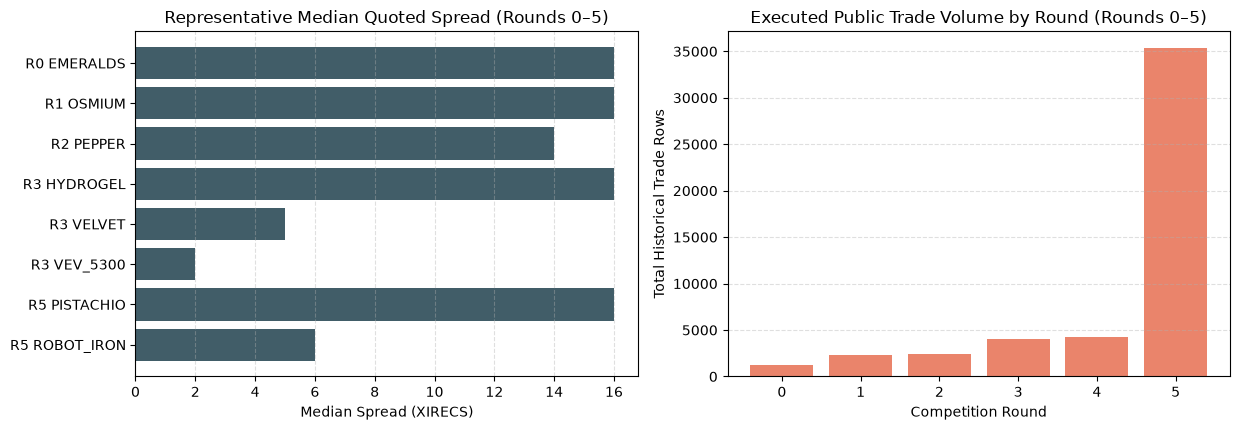

In [3]:
rep_targets = [
    (0, -1, "EMERALDS", "R0 EMERALDS"),
    (1, -1, "ASH_COATED_OSMIUM", "R1 OSMIUM"),
    (2, 0, "INTARIAN_PEPPER_ROOT", "R2 PEPPER"),
    (3, 1, "HYDROGEL_PACK", "R3 HYDROGEL"),
    (3, 1, "VELVETFRUIT_EXTRACT", "R3 VELVET"),
    (3, 1, "VEV_5300", "R3 VEV_5300"),
    (5, 2, "SNACKPACK_PISTACHIO", "R5 PISTACHIO"),
    (5, 2, "ROBOT_IRONING", "R5 ROBOT_IRON"),
]
spread_rows = []
for rnd, day, sym, label in rep_targets:
    df_r = loader.load_day_prices(rnd, day)
    b = summarize_order_book(df_r, sym)
    spread_rows.append({"label": label, "spread_med": b.spread_median, "mid_std": round(b.mid_std, 2)})
sp_df = pd.DataFrame(spread_rows)

r5_eda = pd.read_csv(root / "reports" / "tables" / "r5_per_product_eda.csv")
print(f"Round 5 universe loaded: {len(r5_eda)} instruments across {r5_eda['category'].nunique()} categories.")
display(
    r5_eda.groupby("category", as_index=False)
    .agg(
        assets=("symbol", "count"),
        is_spread=("is_spread_med", "mean"),
        is_sigma_diff=("is_sigma_diff", "mean"),
        spread_sigma_ratio=("is_spread_to_sigma", "mean"),
        oos_sigma_diff=("oos_d4_sigma_diff", "mean"),
    )
    .round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
axes[0].barh(sp_df["label"], sp_df["spread_med"], color="#264653", alpha=0.88)
axes[0].invert_yaxis()
axes[0].set_title("Representative Median Quoted Spread (Rounds 0–5)")
axes[0].set_xlabel("Median Spread (XIRECS)")
axes[0].grid(True, axis="x", linestyle="--", alpha=0.4)

tr_tot = m_df[m_df["dataset_type"] == "trades"].groupby("round_num")["row_count"].sum()
axes[1].bar(tr_tot.index.astype(str), tr_tot.values, color="#e76f51", alpha=0.85)
axes[1].set_title("Executed Public Trade Volume by Round (Rounds 0–5)")
axes[1].set_xlabel("Competition Round")
axes[1].set_ylabel("Total Historical Trade Rows")
axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()